# Solutions to the exercises of Chapter 14

Sample solutions for [Chapter 14, Nematic liquid crystals](../../notebooks/part3_soft_materials/14_nematic_liquid_crystals.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.linalg import eigh_tridiagonal
from scipy.optimize import brentq
from scipy.special import j1

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## Exercise 1. A display cell

With $\chi E^2 = \varepsilon_0\Delta\varepsilon E^2$, Eq. (14.4) gives $E_c = (\pi/d)(K_2/\varepsilon_0\Delta\varepsilon)^{1/2}$, and Eq. (14.6) gives the field
for a chosen switch-on time, $\varepsilon_0\Delta\varepsilon E^2 = \gamma_1/\tau_{\rm on} + K_2\pi^2/d^2$.

In [2]:
K2, gamma1, deps, d, eps0 = 3e-12, 0.1, 10.0, 4e-6, 8.854e-12
Ec = math.pi / d * math.sqrt(K2 / (eps0 * deps))
tau0 = gamma1 * d**2 / (math.pi**2 * K2)
E_1ms = math.sqrt((gamma1 / 1e-3 + K2 * math.pi**2 / d**2) / (eps0 * deps))
print(f"threshold field E_c = {Ec:.3e} V/m = {Ec * 1e-6:.3f} V/um")
print(f"switch-off time tau_0 = {tau0 * 1e3:.1f} ms")
print(f"field for tau_on = 1 ms: {E_1ms:.3e} V/m = {E_1ms / Ec:.2f} E_c")

threshold field E_c = 1.446e+05 V/m = 0.145 V/um
switch-off time tau_0 = 54.0 ms
field for tau_on = 1 ms: 1.073e+06 V/m = 7.42 E_c


The threshold is about 0.14 V per micrometre, so a few volts across electrodes some
ten micrometres apart switch the cell. The switch-off takes 54 ms and cannot
be shortened by the field: it is set by the cell thickness and the material,
$\gamma_1d^2/\pi^2K_2$. The switch-on can be made fast by driving the cell well above the
threshold; 1 ms needs about seven times the threshold field. This asymmetry is why
fast displays use thin cells and materials with a small $\gamma_1/K$.

## Exercise 2. Beyond the threshold

In [3]:
phi, a, m = sp.symbols("phi a m", positive=True)
K_series = sp.pi / 2 * (1 + m / 4 + sp.Rational(9, 64) * m**2)                 # K(m), m = k^2, to second order
h_exact = sp.series((2 / sp.pi * K_series).subs(m, sp.sin(phi) ** 2), phi, 0, 6).removeO()
h_trial = sp.series(sp.sqrt(a / sp.besselj(1, 2 * a)), a, 0, 6).removeO()
print("exact:     h - 1 =", sp.expand(h_exact - 1))
print("one mode:  h - 1 =", sp.expand(h_trial - 1))
print("check of the series of K(m):", sp.series(sp.elliptic_k(m), m, 0, 3))
for x in (0.1, 0.2, 0.4):
    h = float(h_exact.subs(phi, x))
    print(f"phi_m = {x}: h from the series {h:.6f}, exact twist at that h {on.freedericksz_twist_angle(h):.6f};"
          f"  one-mode amplitude at that h {brentq(lambda y: y - h * h * j1(2 * y), 1e-9, 1.9):.6f}")

exact:     h - 1 = 11*phi**4/192 + phi**2/4
one mode:  h - 1 = 5*a**4/96 + a**2/4
check of the series of K(m): pi/2 + pi*m/8 + 9*pi*m**2/128 + O(m**3)
phi_m = 0.1: h from the series 1.002506, exact twist at that h 0.100000;  one-mode amplitude at that h 0.100010
phi_m = 0.2: h from the series 1.010092, exact twist at that h 0.199990;  one-mode amplitude at that h 0.200075
phi_m = 0.4: h from the series 1.041467, exact twist at that h 0.399700;  one-mode amplitude at that h 0.400398


Both start with $h - 1 = \tfrac14\phi_m^2$, so the trial is exact at the threshold. At the next order
the trial's coefficient, $5/96 = 0.052$, is smaller than the exact $11/192 = 0.057$: at a given
field the trial predicts a slightly larger twist. The sine profile spreads the twist
evenly, while the real profile is already beginning to flatten in the middle, which
costs less field energy for the same mid-plane angle. The numbers confirm it: at
$\phi_m = 0.4$ the one-mode amplitude is too large by 0.0007.

## Exercise 3. Switching off

Without field, $\phi_t = \phi_{zz}/\pi^2$ with $\phi = 0$ at the walls, so $\phi = \sum b_j\sin(j\pi z)\,e^{-j^2t}$, with the
coefficients $b_j$ of the initial profile. Only odd $j$ appear, and at the mid-plane
$\sin(j\pi/2) = \pm1$ alternates in sign.

first coefficients b_1, b_3, b_5: 1.8551, 0.3750, 0.1101
mid-plane twist at t = 0: series 1.5633, finite differences 1.5633
initial decay rate of the mid-plane twist: 0.083 (the slowest mode alone: 1)
largest difference series - finite differences: 3.6e-06


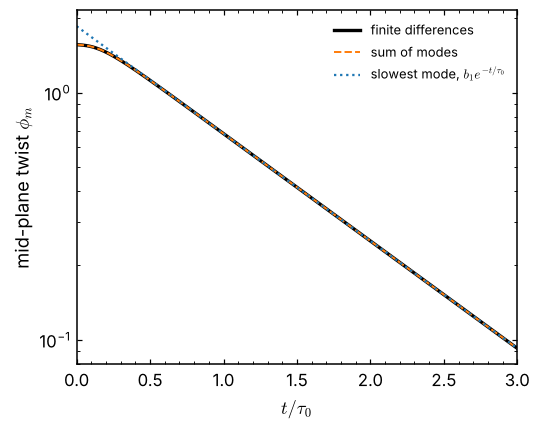

In [4]:
n = 399
zz = np.arange(1, n + 1) / (n + 1)
h = 4.0
start = on.director_fd(0.01 * np.sin(np.pi * zz), np.array([0.0, 400.0]), lambda p: h * h * np.sin(p) * np.cos(p), 1 / np.pi**2)[-1]
j = 2 * np.arange(60) + 1
b = 2 * np.array([np.sum(start * np.sin(k * np.pi * zz)) / (n + 1) for k in j])
sign = np.sin(j * np.pi / 2)
t = np.linspace(0, 3, 301)
series = np.array([np.sum(b * sign * np.exp(-j**2 * s)) for s in t])
fd = on.director_fd(start, t, lambda p: 0 * p, 1 / np.pi**2)[:, n // 2]
print(f"first coefficients b_1, b_3, b_5: {b[0]:.4f}, {b[1]:.4f}, {b[2]:.4f}")
print(f"mid-plane twist at t = 0: series {series[0]:.4f}, finite differences {fd[0]:.4f}")
print(f"initial decay rate of the mid-plane twist: {-(series[1] - series[0]) / (t[1] - t[0]) / series[0]:.3f} (the slowest mode alone: 1)")
print(f"largest difference series - finite differences: {np.max(np.abs(series - fd)):.1e}")

fig, ax = plt.subplots(figsize=(4.8, 3.8))
ax.semilogy(t, fd, "k-", lw=2.2, label="finite differences")
ax.semilogy(t, series, "C1--", lw=1.3, label="sum of modes")
ax.semilogy(t, b[0] * np.exp(-t), "C0:", lw=1.5, label=r"slowest mode, $b_1e^{-t/\tau_0}$")
ax.set_xlabel(r"$t/\tau_0$"); ax.set_ylabel(r"mid-plane twist $\phi_m$"); ax.set_xlim(0, 3)
ax.legend(loc="upper right", fontsize=8.5)
plt.show()

**Figure S14.1.** Switching off from the steady state at $h = 4$.

The steady state at a strong field is nearly flat in the middle, $\phi \approx \pi/2$, so its first
coefficient is close to that of a square wave, $b_1 \approx (4/\pi)(\pi/2) = 2$, larger than the
mid-plane twist itself; the harmonics, with alternating signs at the mid-plane, make
up the difference. They decay $9$, $25$, … times faster, and as they disappear the
mid-plane twist loses a negative contribution: at first it decays twelve times more
slowly than the slowest mode alone (rate 0.083 instead of 1). Physically, the middle
of the cell is flat and does not feel the walls; it starts to relax only when the
relaxation, entering from the walls, reaches it, as in the diffusion problems of
Chapter 5. After that the slowest mode takes over. The fall time is almost independent
of the field because the equation without field is linear, and above $h \approx 2$ the starting
profile hardly changes: the director has already turned along the field in most of
the cell.

## Exercise 4. Weak anchoring

With the anchoring energy, the free energy (14.1) gains the surface terms
$\tfrac12W\sin^2\phi(0) + \tfrac12W\sin^2\phi(d)$. In the Rayleighian the values of $\phi$ at the walls are now free,
and the surface terms of $\dot A$ must vanish for every $\dot\phi(0)$ and $\dot\phi(d)$:

$$ -K_2\phi'(0) + W\sin\phi(0)\cos\phi(0) = 0 , \qquad K_2\phi'(d) + W\sin\phi(d)\cos\phi(d) = 0 , $$

the torque balance at each wall (no viscous torque acts on a surface without
thickness). For a small twist, $K_2\phi' = W\phi$ at $z = 0$. At the threshold the
twist is $\phi \propto \cos[q(z - d/2)]$ with $\chi F_c^2 = K_2q_c^2$, and the condition at the wall gives
$K_2q\sin(qd/2) = W\cos(qd/2)$, that is

$$ \frac{q_cd}{2}\tan\frac{q_cd}{2} = \frac{d}{2b} , \qquad b = \frac{K_2}{W} . $$

For strong anchoring, $b \to 0$, $q_cd \to \pi$. The cell checks the condition against the
lowest eigenvalue of the discretised operator with the Robin condition.

In [5]:
def threshold_from_condition(b_over_d):
    x = brentq(lambda x: x * math.tan(x) - 1 / (2 * b_over_d), 1e-9, math.pi / 2 - 1e-12)
    return 2 * x                                                      # q_c d

def threshold_from_operator(b_over_d, n=4000):
    # -phi'' on 0 < z < 1 with phi' = phi/b at z = 0 and -phi' = phi/b at z = 1 (ghost points)
    dz = 1.0 / n
    main = np.full(n + 1, 2.0)
    off = np.full(n, -1.0)
    main[0] = main[-1] = 2.0 + 2 * dz / b_over_d
    # symmetrise the boundary rows (factor 1/2 on the end points of the energy)
    main[0] /= 2; main[-1] /= 2
    weights = np.ones(n + 1); weights[0] = weights[-1] = 0.5
    scale = 1 / np.sqrt(weights)
    lam = eigh_tridiagonal(main * scale**2, off * scale[:-1] * scale[1:], select="i", select_range=(0, 0))[0][0]
    return math.sqrt(lam) / dz

print("   b/d     q_c d (condition)   q_c d (operator)   F_c / F_c(strong)")
for b_over_d in (0.01, 0.05, 0.1, 0.3, 1.0):
    qc = threshold_from_condition(b_over_d)
    print(f"  {b_over_d:5.2f}       {qc:.5f}            {threshold_from_operator(b_over_d):.5f}           {qc / math.pi:.4f}")

   b/d     q_c d (condition)   q_c d (operator)   F_c / F_c(strong)
   0.01       3.08001            3.08001           0.9804
   0.05       2.85774            2.85774           0.9096
   0.10       2.62768            2.62768           0.8364
   0.30       2.04223            2.04223           0.6501
   1.00       1.30654            1.30654           0.4159


For $b = d/10$ the threshold falls by 16 %. Weak anchoring lets the director turn
already at the walls, so a longer wave fits in the cell and less field is needed. The
extrapolation length $b$ has a simple meaning: the twist profile, continued beyond
the wall, would vanish a distance $b$ behind it, as if the cell were $d + 2b$ thick with
strong anchoring. This is why $q_cd \approx \pi d/(d + 2b)$ when $b \ll d$.